In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi




# CM125

In [4]:
prefix='/mnt/staging/'

mouse='cm125'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
all_ind = sensory_ind.copy()
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
all_ind.update(extra_ind)
all_ind['LM']=all_ind['mouth']

figure_config_root = str(PREPARES / "config") + "/"
load_path = str(PREPARES / "heterogeneity/all-seed") + "/"
save_path = str(PREPARES / "heterogeneity-contours") + "/"

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'

In [6]:
corr_maps_dict={};sensory_ind_dict={};node_coords_dict={}
corr_maps_dict[mouse]={}
bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV','LT','RT']

if mouse in ['cm125']:
    sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
    sensory_ind['LM']=sensory_ind['mouth']
    sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
    M2_ind['LM'] = M2_ind['mouth']
    M2_ind['RM'] = extra_extra_ind['right_mouth_motor']
    sensory_ind['LV']=extra_ind['LV']
    sensory_ind['RV']=extra_ind['RV']
else:
    sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)

In [105]:
corr_maps_dict={};sensory_ind_dict={};node_coords_dict={}
corr_maps_dict[mouse]={}
bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV','LT','RT']

if mouse in ['cm125','cm126','cm128']:
    sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
    sensory_ind['LM']=sensory_ind['mouth']
    sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
    M2_ind['LM'] = M2_ind['mouth']
    M2_ind['RM'] = extra_extra_ind['right_mouth_motor']
    sensory_ind['LV']=extra_ind['LV']
    sensory_ind['RV']=extra_ind['RV']
else:
    sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)
sensory_ind_dict[mouse] = sensory_ind


with h5py.File(load_path+mouse+'_all_corr_maps_dict.h5', 'r') as hf:
    for i in range(len(bdp_w_order)):
        bdp=bdp_w_order[i]
        region_number = sensory_ind[bdp]
        try:
            corr_maps_dict[mouse][bdp+'-sensory'] = np.array(hf['roi-'+str(region_number)])
        except:
            corr_maps_dict[mouse][bdp+'-sensory'] = np.array(hf['roi_roi_'+str(region_number)])
corr_maps_dict = corr_maps_dict['cm125']

In [106]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up


In [107]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)
def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()


In [108]:
sensory_ind

{'LW': 39,
 'mouth': 5,
 'LFP': 77,
 'RFP': 400,
 'RHP': 316,
 'LHP': 117,
 'RW': 460,
 'RN': 495,
 'LN': 7,
 'RT': 304,
 'LT': 151,
 'RM': 494,
 'LM': 5,
 'LV': 65,
 'RV': 406}

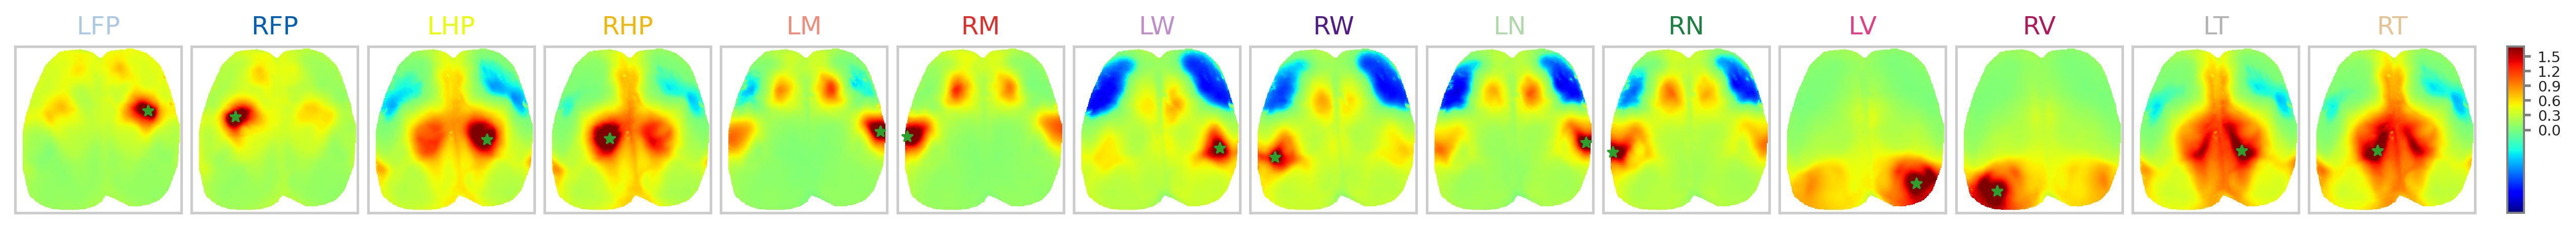

In [109]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.rcParams['svg.fonttype'] = 'none'

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=5

x_start = x_offset
for i_ax in range(14):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    
ax99 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+2])


# bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN']
divnorm=colors.TwoSlopeNorm(vmin=-0.2, vcenter=0., vmax=1.7)
for i in range(14):
    bdp=bdp_w_order[i]
    region_number = sensory_ind[bdp]
    exec("sbp{}=ax{}.imshow(np.arctanh(corr_maps_dict[bdp+'-sensory']),cmap='jet',norm=divnorm)".format(i,i))
    exec("ax{}.set_title(bdp,color=palatte_dict[bdp])".format(i))
    exec("ax{}.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=25, c='tab:green', zorder=2)".format(i))

cb = fig.colorbar(sbp7, cax=ax99,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=7)
cb.locator = tick_locator
cb.update_ticks()
ax99.set_aspect(10)



In [110]:
pixels_per_mm=29

In [111]:
# fetch_path=str(PREPARES / "heterogeneity") + "/"
# brightest_frontline_ind = load_pickle(fetch_path+'brightest_frontline_ind-'+mouse)

In [112]:
from sklearn.preprocessing import minmax_scale
from skimage import measure

## Experiment

In [113]:
from scipy.ndimage import label, center_of_mass


with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
        mask_midline = np.array(f_midline['mask_midline']).T


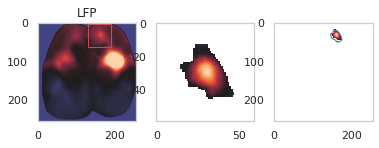

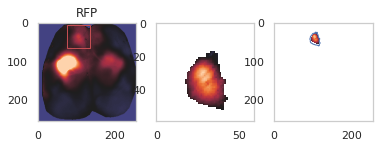

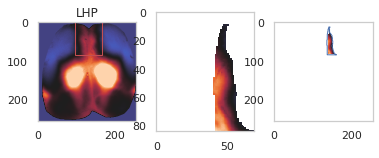

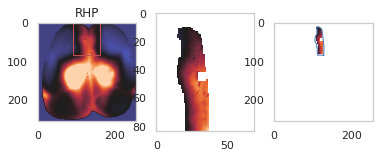

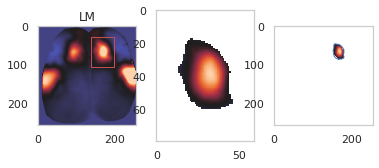

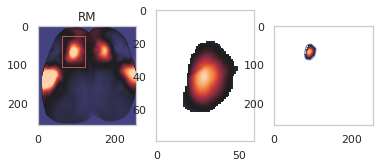

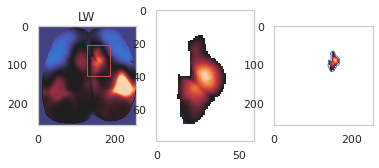

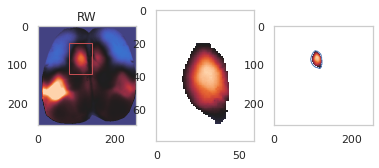

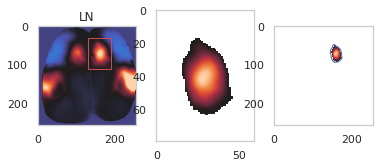

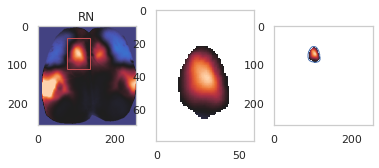

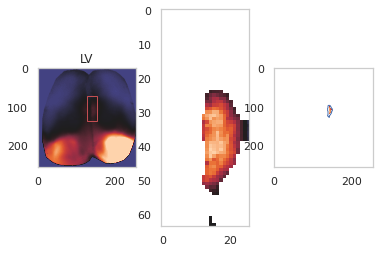

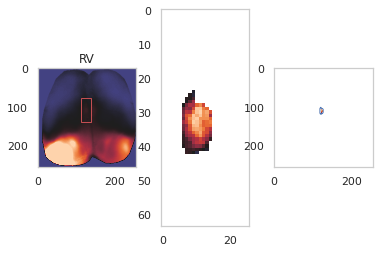

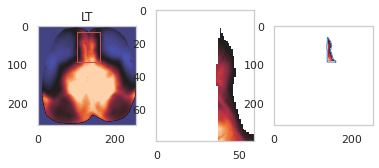

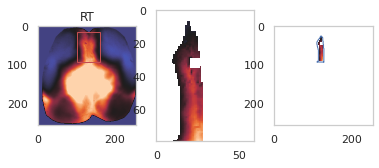

In [114]:
sns.set_style("whitegrid", {'axes.grid' : False})
dict_coords_y0 = {}
dict_coords_x0 = {}
dict_coords_xmin = {}
dict_coords_xmax = {}
dict_coords_ymin = {}
dict_coords_ymax = {}
w=60;h=60
dict_M2_full = {}
clean_contours={}
contours={}
dict_threshold = {}
dict_Z={}
for i in range(14):
    key=bdp_w_order[i]
    ind = sensory_ind[bdp]
    if key in ['LHP','RHP','LT','RT']:
        w=60;
        h = 80
    elif key in ['LV','RV']:
        w=27;
        h=65
    else:
        w=60;
        
    dict_coords_y0[key]=node_coords[M2_ind[key],0]
    dict_coords_x0[key]=node_coords[M2_ind[key],1]
    dict_coords_xmin[key] = int(dict_coords_x0[key]-int(w/2)) if dict_coords_x0[key]-int(w/2)>=0 else 0
    dict_coords_xmax[key] = int(dict_coords_x0[key]+int(w/2)) if dict_coords_x0[key]+int(w/2)<=256 else 256
    dict_coords_ymin[key] = int(dict_coords_y0[key]-int(h/2)) if dict_coords_y0[key]-int(h/2) >=0 else 0
    dict_coords_ymax[key] = int(dict_coords_y0[key]+int(h/2)) if dict_coords_y0[key]+int(h/2) <=256 else 256
    if key in ['LHP','RHP']:
        dict_coords_xmin[key] = int(dict_coords_x0[key]-int(w/2))-10 if dict_coords_x0[key]-int(w/2)-10 >=0 else 0
        dict_coords_xmax[key] = int(dict_coords_x0[key]+int(w/2)) if dict_coords_x0[key]+int(w/2)<=256 else 256
        dict_coords_ymax[key] = int(dict_coords_y0[key]+int(h/2))-25 if dict_coords_y0[key]+int(h/2)-25 <=256 else 256
        dict_coords_ymin[key] = int(dict_coords_y0[key]-int(h/2))-30 if dict_coords_y0[key]-int(h/2)-30 >=0 else 0

    
for i in range(14):
    key=bdp_w_order[i]
    ind = sensory_ind[bdp]
    fig, (ax,ax1,ax2) = plt.subplots(1,3)
    toy = np.arctanh(corr_maps_dict[key+'-sensory'])
    # toy = corr_maps_dict[key+'-sensory']
    toy_fillna = np.nan_to_num(toy)
    ax.imshow(toy_fillna,vmin=-0.5,vmax=1,cmap='icefire')
    rect = patches.Rectangle((dict_coords_xmin[key], dict_coords_ymin[key]),
                              dict_coords_xmax[key] - dict_coords_xmin[key], 
                             dict_coords_ymax[key]-dict_coords_ymin[key], linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(key)
    

    Z = toy_fillna[dict_coords_ymin[key]:dict_coords_ymax[key],
                   dict_coords_xmin[key]:dict_coords_xmax[key]]

#     # --- UPDATED BLOCK ---
#     if key in ['LHP', 'RHP', 'LT', 'RT']:
#         # APPLY MIDLINE CUT (Important for HP/Tail)
#         # This multiplies the crop by the mask (NaNs in center), physically separating L/R blobs
#         mask_slice = mask_midline[dict_coords_ymin[key]:dict_coords_ymax[key], 
#                                   dict_coords_xmin[key]:dict_coords_xmax[key]]
        
#         Z = np.multiply(Z, mask_slice)
        
#         # Create a temp mask ignoring NaNs to find the newly separated islands
#         temp_mask = (Z > 0) & (~np.isnan(Z))
#         labeled_array, num_features = label(temp_mask)
        
#         if num_features > 0:
#             # center_of_mass with a list/range ALWAYS returns a list of tuples
#             centers = center_of_mass(temp_mask, labeled_array, list(range(1, num_features+1)))

#             # LOGIC: 
#             # LHP/LT (Left Body) -> Signal is in RIGHT Hemisphere -> Max X
#             # RHP/RT (Right Body) -> Signal is in LEFT Hemisphere -> Min X
#             if key in ['LHP', 'LT']:
#                 best_idx = np.argmax([c[1] for c in centers]) # Rightmost blob
#             else: # RHP, RT
#                 best_idx = np.argmin([c[1] for c in centers]) # Leftmost blob
            
#             target_label = best_idx + 1
            
#             # Update Z: Keep ONLY the target blob, turn the rest to NaN
#             keep_mask = (labeled_array == target_label)
#             Z[~keep_mask] = np.nan
    # -------------------------
# --- UPDATED BLOCK ---
    if key in ['LHP', 'RHP', 'LT', 'RT']:
        # APPLY MIDLINE CUT (Important for HP/Tail)
        # This multiplies the crop by the mask (NaNs in center), physically separating L/R blobs
        mask_slice = mask_midline[dict_coords_ymin[key]:dict_coords_ymax[key], 
                                  dict_coords_xmin[key]:dict_coords_xmax[key]]
        
        Z = np.multiply(Z, mask_slice)
        
        # Create a temp mask ignoring NaNs to find the newly separated islands
        temp_mask = (Z > 0) & (~np.isnan(Z))
        labeled_array, num_features = label(temp_mask)
        
        if num_features > 0:
            # center_of_mass with a list/range ALWAYS returns a list of tuples
            centers = center_of_mass(temp_mask, labeled_array, list(range(1, num_features+1)))

            # LOGIC: 
            # LHP/LT (Left Body) -> Signal is in RIGHT Hemisphere -> Max X
            # RHP/RT (Right Body) -> Signal is in LEFT Hemisphere -> Min X
            if key in ['LHP', 'LT']:
                best_idx = np.argmax([c[1] for c in centers]) # Rightmost blob
            else: # RHP, RT
                best_idx = np.argmin([c[1] for c in centers]) # Leftmost blob
            
            target_label = best_idx + 1

            # --- NEW: UPDATE M2_ind ---
            # 1. Get the local centroid (y, x)
            local_y_float, local_x_float = centers[best_idx]
            local_y = int(local_y_float)
            # 2. Find all valid X coordinates for this specific Y row within the blob
            valid_xs = np.where(keep_mask[local_y, :])[0]
            if len(valid_xs) > 0:
                if key in ['LHP', 'LT']:
                    # Right Hemisphere blob -> Midline is left -> find max X
                    local_x = np.max(valid_xs)
                else:
                    # Left Hemisphere blob -> Midline is right -> find min X
                    local_x = np.min(valid_xs)
            else:
                # Fallback to centroid X if something weird happens with the row
                local_x = int(local_x_float)
            # 3. Convert local cropped coordinates back to global 256x256 coordinates
            global_y = dict_coords_ymin[key] + local_y
            global_x = dict_coords_xmin[key] + local_x
            # 4. Find the closest index in node_coords using Euclidean distance
            distances = np.sqrt((node_coords[:, 0] - global_y)**2 + (node_coords[:, 1] - global_x)**2)
            new_M2_ind = int(np.argmin(distances))

            # 5. Reset the M2_ind dictionary with the new index
            M2_ind[key] = new_M2_ind
            # --------------------------
            
            # Update Z: Keep ONLY the target blob, turn the rest to NaN
            keep_mask = (labeled_array == target_label)
            Z[~keep_mask] = np.nan
    # ------------------------- 
    if key in ['LHP','RHP','LT','RT']:  
        threshold = np.percentile(Z[~np.isnan(Z)], 40)
    else:
        threshold = np.percentile(Z[~np.isnan(Z)], 70)
    
    dict_threshold[key] = threshold
    
    
    mask_here = np.array(Z>threshold).astype('float')
    mask_here[mask_here==0]=np.nan
    
    data_here = np.multiply(Z,mask_here)
    
    from scipy.ndimage.filters import gaussian_filter
    sigma = 0.4
    data_here = gaussian_filter(data_here, sigma)
    shape = data_here.shape
    data_here = minmax_scale(data_here.ravel(), feature_range=(0.1,1)).reshape(shape)

    ax1.imshow(data_here,vmin=-0.5,vmax=1,cmap='icefire')
    
    
    M2_full=np.zeros((256,256));M2_full[:]=np.nan
    M2_full_before_norm = M2_full.copy()
    M2_full[dict_coords_ymin[key]:dict_coords_ymax[key],
                   dict_coords_xmin[key]:dict_coords_xmax[key]]=data_here


    dict_M2_full[key]=M2_full
    dict_Z[key] = Z
    ax2.imshow(M2_full,vmin=-0.5,vmax=1,cmap='icefire')

    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(M2_full>0.2)
    contours[key] = measure.find_contours(filled_bw, 0.8)

    
    clean_contours[key]=[]
    for i_contour,contour in enumerate(contours[key]):
        # print(len(contour))
        # if np.logical_or(len(np.where(np.array(contour[:,0]>100)==True)[0]),len(contour)<20):
        if len(contour)<30:
            # print('place holder')
            a=1
        else:
            clean_contours[key].append(contours[key][i_contour])

    for contour in clean_contours[key]:
        ax2.plot(contour[:,1],contour[:,0],linewidth=1)


In [115]:
dict_threshold_M2 = dict_threshold;

# Redo HP M2s with Gaussiann fit 

In [83]:
# # (132,122) #bregma location
# x_axis = np.divide(np.linspace(-132,256-132-1,256),pixels_per_mm)
# y_axis = np.divide(np.linspace(256-122-1,-122,256),pixels_per_mm)

# extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]


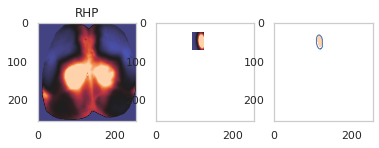

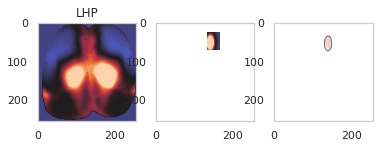

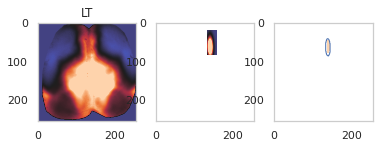

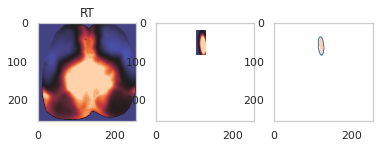

In [203]:
# from lmfit import Model
# w=18;h=80

    
# dict_fit_result_M2 = {};
# clean_contours_fit={}

# for key in ['RHP','LHP','LT','RT']:
#     fig, (ax,ax1,ax2) = plt.subplots(1,3)
#     toy = np.arctanh(corr_maps_dict[key+'-sensory'])
#     toy_fillna = np.nan_to_num(toy)
#     ax.imshow(toy_fillna,vmin=-0.5,vmax=1,cmap='icefire')
#     ax.set_title(key)
    
    
#     M2_full = dict_Z[key]
    
#     from scipy.ndimage import center_of_mass
#     mask = ~np.isnan(M2_full)
#     if np.sum(mask) == 0:
#         midline = M2_full.shape[1] // 2  # fallback
#     else:
#         cy, cx = center_of_mass(mask)  # returns (row, col)
#         midline = int(round(cx))

#     ############################################
#     if key in ['LHP', 'LT']:
#         M2_half = M2_full[:, midline:]
#     elif key in ['RHP', 'RT']:
#         M2_half = M2_full[:, :midline]


#     # Now we convert our 2D Gaussian to an lmfit model
#     fmodel = Model(f, independent_vars=('x','y'))
    
#     from scipy.ndimage.filters import gaussian_filter
#     sigma = 0.5
#     # sigma = 1.5
#     data_here = gaussian_filter(M2_half, sigma)
#     shape = data_here.shape
#     data_here = minmax_scale(data_here.ravel(), feature_range=(0.1,1)).reshape(shape)
    
#     # Get bounding box of non-NaN region
#     mask = ~np.isnan(M2_half)
#     ys, xs = np.where(mask)

#     if len(xs) == 0 or len(ys) == 0:
#         continue  # skip if empty

#     ymin, ymax = ys.min(), ys.max() + 1
#     xmin, xmax = xs.min(), xs.max() + 1

#     # Extract cropped data and axis ranges
#     Z = data_here[ymin:ymax, xmin:xmax]
#     Y = y_axis[ymin:ymax]
#     X = x_axis[xmin:xmax]
#     Xg, Yg = np.meshgrid(X, Y)
    
    
#     Ae, x0e, y0e, sxe, sye, thetae = getest2DGF(Xg, Yg, Z)
#     # print("Found initial estimates: ", Ae, x0e, y0e, sxe, sye, thetae)
#     Ae=2
#     dict_fit_result_M2[key] = fmodel.fit(Z, x=Xg, y=Yg, x0=x0e, y0=y0e, 
#                         sigma_x=sxe, sigma_y=sye, theta=thetae,
#                        nan_policy='omit')
#     fit = fmodel.func(Xg, Yg, **dict_fit_result_M2[key].best_values)
    

#     # 1. Get ROI boundaries
#     xmin = dict_coords_xmin[key]
#     xmax = dict_coords_xmax[key]
#     ymin = dict_coords_ymin[key]
#     ymax = dict_coords_ymax[key]

#     # 2. Prepare full-sized ROI container
#     roi_h = ymax - ymin
#     roi_w = xmax - xmin
#     fit_full = np.full((roi_h, roi_w), np.nan)
    
#     # 3. Place half into correct side
#     if key in ['LHP', 'LT']:
#         fit_full[:, midline:] = fit  # right half
#     elif key in ['RHP', 'RT']:
#         fit_full[:, :midline] = fit  # left half
        
#     # 4. Put into 256x256 canvas
#     fitted_canvas = np.full((256, 256), np.nan)
#     fitted_canvas[ymin:ymax, xmin:xmax] = fit_full
    
#     #######
#     dict_fit_result_M2[key] = fitted_canvas
#     ax1.imshow(fitted_canvas,vmin=-0.5,vmax=1,cmap='icefire')
    
    
#     filled_bw = scipy.ndimage.morphology.binary_fill_holes(fitted_canvas>0.8)
#     clean_contours_fit[key] = measure.find_contours(filled_bw, 0.8)

    
#     # do it again with nan
#     mask_here = np.array(filled_bw).astype('float')
#     mask_here[mask_here==0]=np.nan

    
#     dict_fit_result_M2[key]=mask_here
#     ax2.imshow(mask_here,vmin=-0.5,vmax=1,cmap='icefire')
#     for contour in clean_contours_fit[key]:
#         ax2.plot(contour[:,1],contour[:,0],linewidth=1)
    
    

In [33]:
bdp_w_order_new = ['LHP', 'RHP','LFP', 'RFP',  'LM', 'RM', 'LW', 'RW','LT','RT']
just_brain_map = IDX_sorted>0
just_brain_map = just_brain_map.astype(float)
just_brain_map[just_brain_map==0]='nan'

plt.figure(dpi=300)
plt.imshow(just_brain_map,vmin=0,vmax=4400,cmap='gray',extent=extent)



for ikey in range(14):
    key=bdp_w_order[ikey]


    ###### M2 ######
    c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 1)
    c_black_2= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 0.9)
    c_black_3= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 0.1)
    c_white= matplotlib.colors.colorConverter.to_rgba('black',alpha = 0)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black_3,c_black_2,c_black],5120)

    if ikey in [3,2]:
        vmax_value = 1.1
    else:
        vmax_value = 0.8
        
    if key in ['LHP','RHP','LT','RT']:
        plt.imshow(dict_fit_result_M2[key],vmin=0.1,vmax=vmax_value,cmap=cmap_rb,extent=extent) 
    else:
        plt.imshow(dict_M2_full[key],vmin=0.1,vmax=vmax_value,cmap=cmap_rb,extent=extent) 

    y_value = -1-ikey*0.4
    plt.plot(np.linspace(-4,-3,50),np.ones(50)*y_value,color=palatte_dict[key])
    plt.text(-2.8,y_value-0.15,key,color=palatte_dict[key])
# plt.xlim([5,256])

# plt.scatter(0,0)
# for ikey,key in enumerate([ 'LFP', 'LHP', 'mouth', 'LW','nose']):
#     plt.scatter(dict_fit_result[key].best_values['x0'],
#                 dict_fit_result[key].best_values['y0'])

    plt.xlabel=('mm')
    plt.ylabel=('mm')
    plt.scatter(0,0,s=10) #bregma location
    plt.xticks(np.linspace(-4,4,9).astype('int'))
    plt.text(-0.8,0.1,'bregma',color='white',fontsize=8)
    plt.grid('off')
    # plt.scatter(1.5,2.5,s=20,marker='*')

    # for contour in clean_contours[key]:
    #     plt.plot(contour[:,1],contour[:,0],linewidth=1)


NameError: name 'extent' is not defined

<Figure size 1800x1200 with 0 Axes>

In [34]:
sns.set_style("whitegrid", {'axes.grid' : False})

In [116]:
save_pickle(clean_contours,save_path+'clean_contours_'+mouse)
save_pickle(dict_M2_full,
            save_path+'dict_M2_full_'+mouse)
# #for RHP LHP
# save_pickle(dict_fit_result_M2,
#             save_path+'dict_fit_result_M2_'+mouse)
# save_pickle(clean_contours_fit,
#             save_path+'clean_contours_fit_'+mouse)


# Now adding S1 too

In [40]:
dict_coords_y0 = {}
dict_coords_x0 = {}
dict_coords_xmin = {}
dict_coords_xmax = {}
dict_coords_ymin = {}
dict_coords_ymax = {}
w=80
h=100
for key, ind in sensory_ind.items():
    dict_coords_y0[key]=node_coords[sensory_ind[key],0]
    dict_coords_x0[key]=node_coords[sensory_ind[key],1]
    dict_coords_xmin[key] = int(dict_coords_x0[key]-int(w/2)) if dict_coords_x0[key]-int(w/2)>=0 else 0
    dict_coords_xmax[key] = int(dict_coords_x0[key]+int(w/2)) if dict_coords_x0[key]+int(w/2)<=256 else 256
    dict_coords_ymin[key] = int(dict_coords_y0[key]-int(h/2)) if dict_coords_y0[key]-int(h/2) >=0 else 0
    dict_coords_ymax[key] = int(dict_coords_y0[key]+int(h/2)) if dict_coords_y0[key]+int(h/2) <=256 else 256

dict_S1_full={}
clean_contours_S1={}

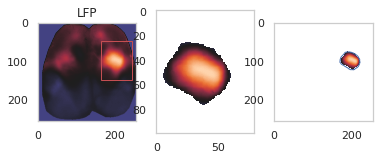

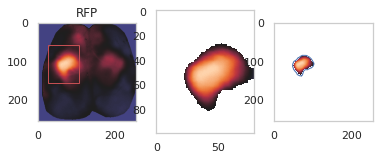

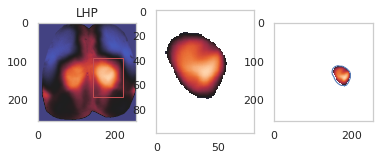

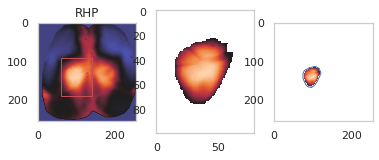

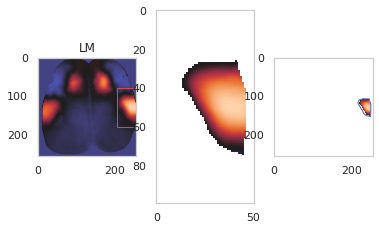

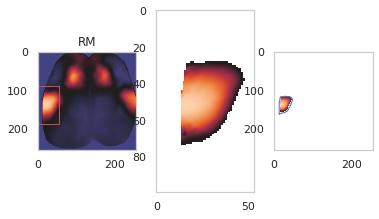

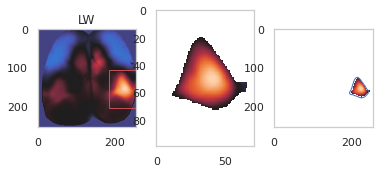

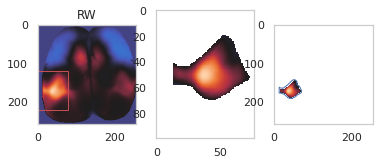

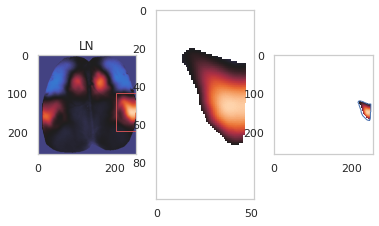

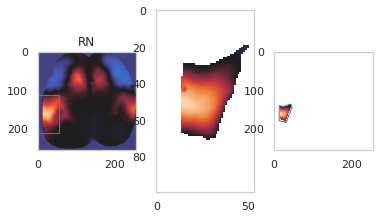

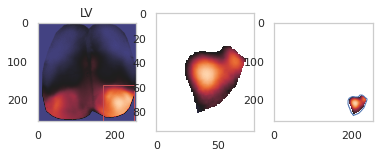

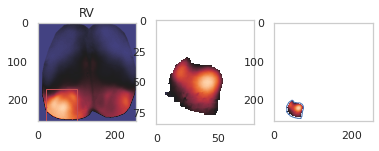

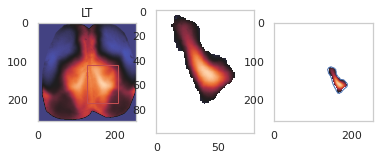

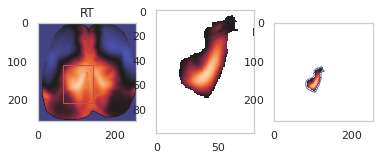

In [41]:
dict_threshold={}
for i in range(14):
    key=bdp_w_order[i]
    ind = sensory_ind[bdp]
    fig, (ax,ax1,ax2) = plt.subplots(1,3)
    # toy = np.arctanh(corr_maps_dict[key+'-sensory'])
    toy = corr_maps_dict[key+'-sensory']
    # toy = corr_maps_dict[key+'-sensory']
    toy_fillna = np.nan_to_num(toy)
    ax.imshow(toy_fillna,vmin=-0.5,vmax=1,cmap='icefire')
    rect = patches.Rectangle((dict_coords_xmin[key], dict_coords_ymin[key]),
                              dict_coords_xmax[key] - dict_coords_xmin[key], 
                             dict_coords_ymax[key]-dict_coords_ymin[key], linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(key)
    

    Z = toy_fillna[dict_coords_ymin[key]:dict_coords_ymax[key],
                   dict_coords_xmin[key]:dict_coords_xmax[key]]


    threshold = np.percentile(Z[~np.isnan(Z)], 70)
    
    dict_threshold[key] = threshold
    
    
    mask_here = np.array(Z>threshold).astype('float')
    mask_here[mask_here==0]=np.nan
    
    data_here = np.multiply(Z,mask_here)
    
    from scipy.ndimage.filters import gaussian_filter
    sigma = 0.4
    data_here = gaussian_filter(data_here, sigma)
    shape = data_here.shape
    data_here = minmax_scale(data_here.ravel(), feature_range=(0.1,1)).reshape(shape)

    ax1.imshow(data_here,vmin=-0.5,vmax=1,cmap='icefire')
    
    
    S1_full=np.zeros((256,256));S1_full[:]=np.nan
    S1_full_before_norm = S1_full.copy()
    S1_full[dict_coords_ymin[key]:dict_coords_ymax[key],
                   dict_coords_xmin[key]:dict_coords_xmax[key]]=data_here
    # M2_full=np.nan_to_num(M2_full,nan=0.8)
    
    # M2_full_before_norm[dict_coords_ymin[key]:dict_coords_ymax[key],
    #                dict_coords_xmin[key]:dict_coords_xmax[key]]=data_here

    dict_S1_full[key]=S1_full
    ax2.imshow(S1_full,vmin=-0.5,vmax=1,cmap='icefire')
    
    
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(S1_full>0.2)
    contours[key] = measure.find_contours(filled_bw, 0.8)

    
    clean_contours_S1[key]=[]
    for i_contour,contour in enumerate(contours[key]):
        # print(len(contour))
        # if np.logical_or(len(np.where(np.array(contour[:,0]>100)==True)[0]),len(contour)<20):
        if len(contour)<30:
            # print('place holder')
            a=1
        else:
            clean_contours_S1[key].append(contours[key][i_contour])

    for contour in clean_contours_S1[key]:
        ax2.plot(contour[:,1],contour[:,0],linewidth=1)


In [42]:
dict_threshold_S1 = dict_threshold

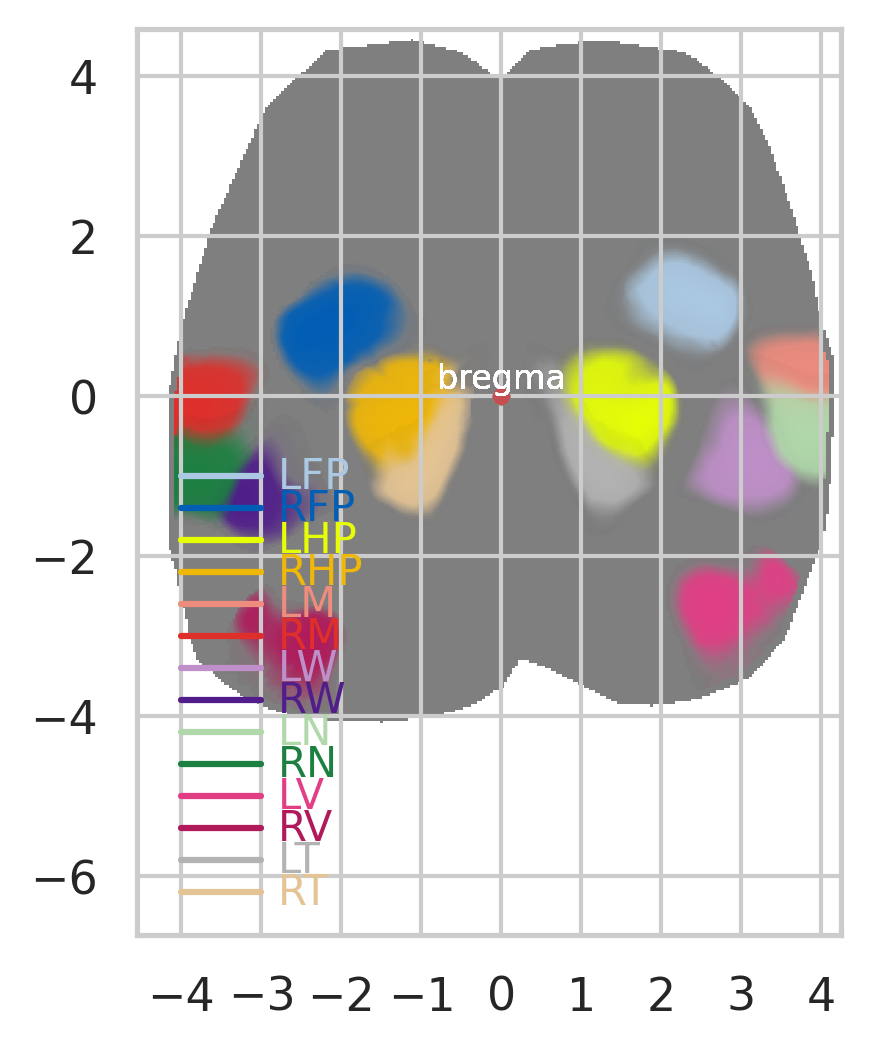

In [43]:
# (132,122) #bregma location
x_axis = np.divide(np.linspace(-132,256-132-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-122-1,-122,256),pixels_per_mm)

extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]

plt.figure(dpi=300)
bdp_w_order_new = ['LHP', 'RHP','LFP', 'RFP',  'LM', 'RM', 'LW', 'RW']
just_brain_map = IDX_sorted>0
just_brain_map = just_brain_map.astype(float)
just_brain_map[just_brain_map==0]='nan'
plt.imshow(just_brain_map,cmap='gray',vmin=0.9,vmax=1.1,extent=extent)


for ikey in range(14):
    key=bdp_w_order[ikey]


    ###### S1 ######
    c_black= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 1)
    c_black_2= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 0.9)
    c_black_3= matplotlib.colors.colorConverter.to_rgba(palatte_dict[key],alpha = 0.1)
    c_white= matplotlib.colors.colorConverter.to_rgba('black',alpha = 0)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black_3,c_black_2,c_black],5120)

    # if ikey in [3,2]:
    #     vmax_value = 1.1
    # else:
    
    vmax_value = 1
    plt.imshow(dict_S1_full[key],vmin=0.1,vmax=vmax_value,cmap=cmap_rb,extent=extent) 

    y_value = -1-ikey*0.4
    plt.plot(np.linspace(-4,-3,50),np.ones(50)*y_value,color=palatte_dict[key])
    plt.text(-2.8,y_value-0.15,key,color=palatte_dict[key])
# plt.xlim([5,256])

# plt.scatter(0,0)
# for ikey,key in enumerate([ 'LFP', 'LHP', 'mouth', 'LW','nose']):
#     plt.scatter(dict_fit_result[key].best_values['x0'],
#                 dict_fit_result[key].best_values['y0'])

    plt.xlabel=('mm')
    plt.ylabel=('mm')
    plt.scatter(0,0,s=10) #bregma location
    plt.xticks(np.linspace(-4,4,9).astype('int'))
    plt.text(-0.8,0.1,'bregma',color='white',fontsize=8)
    plt.grid('off')
    # plt.scatter(1.5,2.5,s=20,marker='*')

    # for contour in clean_contours[key]:
    #     plt.plot(contour[:,1],contour[:,0],linewidth=1)


In [117]:
save_pickle(clean_contours_S1,
            save_path+'clean_contours_S1_'+mouse)

save_pickle(dict_S1_full,
            save_path+'dict_S1_full_'+mouse)




In [118]:
dict_save = {'dict_threshold_M2':dict_threshold_M2,
             'dict_threshold_S1':dict_threshold_S1,
             'sensory_ind': sensory_ind,
             'M2_ind':M2_ind
            }
save_pickle(dict_save,
            save_path+'dict_save_'+mouse)